In [12]:
import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
import random
import matplotlib.pyplot as plt
import time
import os
import glob

def select_alpha_range(target_daily_tasks):
    """根据目标日均任务数，选择合适的退化率范围"""
    if target_daily_tasks <= 5:  # 稀疏
        # return 0.004, 0.006
        return 0.001, 0.002
    elif 6 <= target_daily_tasks <= 12:  # 中等
        return 0.010, 0.013
    else:  # 13+ 密集
        return 0.020, 0.025


def generate_maintenance_plan(N, T, random_seed, target_daily_tasks):
    """生成维护计划（新版本：基于目标任务密度）"""
    random.seed(random_seed)
    
    caissons = [i for i in range(N)]
    initial_p_values = [round(random.uniform(3.2, 3.5), 2) for _ in caissons]
    
    a, b = select_alpha_range(target_daily_tasks)
    alpha_values = [round(random.uniform(a, b), 6) for _ in caissons]
    
    columns = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE']
    data = []
    
    index = 0
    for caisson in range(N):
        current_p = initial_p_values[caisson]
        total_days = 0
        alpha = alpha_values[caisson]
        
        while total_days < T:
            time_to_3_2 = int((current_p - 3.2) / alpha)
            if total_days + time_to_3_2 >= T:
                break
            
            operation = 'x'
            data.append([index, caisson, initial_p_values[caisson], operation, total_days + time_to_3_2])
            index += 1
            total_days += time_to_3_2 + 1
            current_p = 3.5
    
    maintenance_plan = pd.DataFrame(data, columns=columns)
    return maintenance_plan, alpha_values


def run_clustering_analysis(PARAMS, random_seed):
    """完整聚类分析函数"""
    # 生成维护计划 - 使用PARAMS中的target_daily_tasks和random_seed
    df, alpha_values_list = generate_maintenance_plan(
        N=PARAMS['P'], 
        T=PARAMS['T'], 
        random_seed=random_seed,
        target_daily_tasks=PARAMS['target_daily_tasks']
    )
    print(f"Generated {len(df)} tasks for seed {random_seed}")
    
    # alpha_values字典格式
    alpha_values = {i: alpha_values_list[i] for i in range(PARAMS['P'])}
    globals()['alpha_values'] = alpha_values
    globals()['PARAMS'] = PARAMS

    # 🔥 新增：整个聚类过程CPU时间测量
    import time
    clustering_cpu_start = time.process_time()
    
    # 聚类函数
    def clustering_CR(df_window, window_size, window_start):
        if df_window.empty or window_size < 1:
            print(f"warning: window {window_start} has no tasks")
            return df_window

        N_tasks = df_window.shape[0]
        m = gp.Model('Dynamic_Window_Clustering')
        m.setParam('OutputFlag', 0)
        
        data_pos_num = window_size + 1
        theta = m.addVars(N_tasks, data_pos_num, vtype=GRB.BINARY, name='theta')
        cluster = m.addVars(data_pos_num, vtype=GRB.BINARY, name='cluster')

        a = [0] * N_tasks
        b = [0] * N_tasks

        m.setObjective(gp.quicksum(cluster[t] for t in range(data_pos_num)), GRB.MINIMIZE)
        
        m.addConstrs((theta[n, t] <= cluster[t] for n in range(N_tasks) for t in range(data_pos_num)), 
                     name="cluster_activation")
        m.addConstrs((gp.quicksum(theta[n, t] for t in range(data_pos_num)) == 1 for n in range(N_tasks)), 
                     name="task_assignment")
        m.addConstrs((gp.quicksum(theta[n, t] for n in range(N_tasks)) <= PARAMS['Cmax'] for t in range(data_pos_num)), 
                     name="cluster_capacity")

        for n in range(N_tasks):
            csem = int(df_window.iloc[n]['CSEM'])
            local_time = df_window.iloc[n]['window_time']
            a[n] = max(0, local_time - PARAMS['advanced'])
            alpha = alpha_values[csem]
            b[n] = min(data_pos_num, (local_time + int(0.2 / alpha))//2)

        for n in range(N_tasks):
            for t in range(data_pos_num):
                m.addConstr(t * theta[n,t] + a[n] * (1 - theta[n, t]) >= a[n])
                m.addConstr(t * theta[n,t] + b[n] * (1 - theta[n, t]) <= b[n])

        m.setParam('LogToConsole', 1)
        m.setParam('OutputFlag', 1)
        m.setParam('TimeLimit', 300)
        m.setParam('MIPGap', 0.05)

        print(f"Window {window_start}: N_tasks={N_tasks}")
        m.optimize()

        if m.status != GRB.OPTIMAL:
            print(f"Failed to solve window {window_start}: {m.status}")
            return None
        
        centers = {}
        for n in range(N_tasks):
            for t in range(data_pos_num):
                if theta[n, t].x == 1.0:
                    centers[n] = t + window_start
                    break

        index_n_list = df_window.INDEX.tolist()
        for n in range(len(index_n_list)):
            df_window.loc[df_window['INDEX'] == index_n_list[n], 'CENTER'] = centers.get(n, 0)

        return df_window
    
    # 泄漏计算函数
    def calculate_gas_leakage(df, T, use_center=True):
        total_leakage = 0
        for csem in df['CSEM'].unique():
            csem_data = df[df['CSEM'] == csem]
            x_operations = csem_data[csem_data['OPERATION'] == 'x'].sort_values('DATE' if not use_center else 'CENTER')
            if x_operations.empty:
                continue
                
            alpha = alpha_values[int(csem)]

            # 任务间泄漏
            for i in range(1, len(x_operations)):
                current_time = x_operations.iloc[i][('CENTER' if use_center else 'DATE')]
                prev_time = x_operations.iloc[i-1][('CENTER' if use_center else 'DATE')]
                center_diff = current_time - prev_time - 1
                total_leakage += max(0, center_diff) * alpha * PARAMS['K']

            # 开头泄漏
            first_time = x_operations.iloc[0][('CENTER' if use_center else 'DATE')]
            total_leakage += first_time * alpha * PARAMS['K']

            # 结尾泄漏
            last_time = x_operations.iloc[-1][('CENTER' if use_center else 'DATE')]
            leak_time = max(0, T - (last_time + 1))
            total_leakage += leak_time * alpha * PARAMS['K']
        return total_leakage
    
    # 更新次要任务函数
    def update_secondary_tasks(main_df, clustered_df, window_start, window_end):
        for caisson in clustered_df["CSEM"].unique():
            tasks = main_df[
                (main_df['CSEM'] == caisson) & 
                (main_df['DATE'].between(window_start, window_end)) & 
                (main_df['OPERATION'] == 'x')
            ]
            if len(tasks) > 1:
                second_idx = tasks.index[1]
                center_time = clustered_df.loc[clustered_df['CSEM'] == caisson, 'CENTER'].iloc[0]
                alpha = alpha_values[int(caisson)]
                new_date = int(center_time + 1 + (3.5-3.2)/alpha)
                main_df.loc[second_idx, ['DATE', 'CENTER']] = [new_date, new_date]

    # 主逻辑
    df_init = df.copy()
    df_history_list = [df_init]
    sliding_windows_starts = []
    sliding_windows_ends = []
    df['CENTER'] = df['DATE']
    
    window_start = 0
    window_size = PARAMS['window_size']

    while window_start <= PARAMS['T']:
        window_end = min(window_start + window_size, PARAMS['T'])
        sliding_windows_starts.append(window_start)
        sliding_windows_ends.append(window_end)
        
        mask = (df['DATE'] >= window_start) & (df['DATE'] <= window_end) & (df['OPERATION']== 'x')
        window_df = df.loc[mask].copy()
        if window_df.empty:
            break
            
        window_df['window_time'] = window_df['DATE'] - window_start
        first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])

        clustered_df = clustering_CR(first_tasks, window_size, window_start)
        
        if clustered_df is not None:
            center_map = clustered_df.set_index('INDEX')['CENTER']
            df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)
            update_secondary_tasks(df, clustered_df, window_start, window_end)
        
        # 滑动窗口逻辑
        second_dates = []
        if clustered_df is not None:
            for caisson in clustered_df["CSEM"].unique():
                tasks = df[(df['CSEM'] == caisson) & 
                          (df['OPERATION'] == 'x') &
                          (df['DATE'].between(window_start, window_end))].sort_values('DATE')
                if len(tasks) > 1:
                    second_dates.append(tasks.iloc[1]['DATE'])
        
        window_start = min(second_dates) if second_dates else window_start + window_size
        df_history_list.append(df.copy())
        
        if window_end >= PARAMS['T']:
            break
    
    # 处理未分配任务
    mask_remain = (df['OPERATION'] == "x") & (df['CENTER'] == df['DATE'])
    df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']

    # 🔥 聚类过程CPU时间结束
    clustering_cpu_end = time.process_time()
    total_clustering_cpu_time = clustering_cpu_end - clustering_cpu_start

    # 计算泄漏
    leakage_before = calculate_gas_leakage(df_init, PARAMS['T'], use_center=False)
    leakage_after = calculate_gas_leakage(df, PARAMS['T'], use_center=True)
    reduction = leakage_before - leakage_after
    reduction_pct = (reduction / leakage_before * 100) if leakage_before > 0 else 0
    
    return {
        'final_df': df,
        'df_history_list': df_history_list,
        'sliding_windows_starts': sliding_windows_starts,
        'sliding_windows_ends': sliding_windows_ends,
        'alpha_values': alpha_values_list,
        'maintenance_plan': df_init,
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'reduction': reduction,
        'reduction_pct': reduction_pct,
        'total_clustering_cpu_time': total_clustering_cpu_time
    }


# 🔥 🔥 🔥 新增：N敏感性分析主函数（适配你的模型）
def run_N_sensitivity_analysis_MIMAR(base_params, task_densities, N_values, seeds, output_dir='N_sensitivity_MIMAR_results'):
    """固定T，对每个任务密度做N敏感性分析 - MIMAR模型适配版"""
    
    # 创建输出目录
    os.makedirs(output_dir, exist_ok=True)
    
    all_results = []
    
    for target_daily_tasks in task_densities:
        print(f"\n{'='*60}")
        print(f"🔍 MIMAR - 任务密度: {target_daily_tasks} tasks/day")
        print(f"{'='*60}")
        
        density_results = []
        
        for N in N_values:
            print(f"\n  📊 Testing N={N}...")
            
            # 🔥 适配你的参数格式：P=N
            params_template = base_params.copy()
            params_template['P'] = N  # 🔥 关键修改
            params_template['target_daily_tasks'] = target_daily_tasks
            
            # 🔥 文件名格式（与你的模型匹配）
            filename = f"{output_dir}/density_{target_daily_tasks}_N_{N}_all_seeds.csv"
            
            # 🔥 调用你的run_analysis_with_csv_export
            result_df = run_analysis_with_csv_export(
                params_template, seeds, output_filename=filename
            )
            
            # 🔥 添加N和密度列
            result_df['N'] = N
            result_df['target_daily_tasks'] = target_daily_tasks
            
            density_results.append(result_df)
            print(f"     ✅ N={N} results saved: {filename}")
        
        # 🔥 每个密度汇总所有N
        density_summary = pd.concat(density_results, ignore_index=True)
        density_summary_filename = f"{output_dir}/SUMMARY_density_{target_daily_tasks}_all_N.csv"
        density_summary.to_csv(density_summary_filename, index=False)
        print(f"  📁 Density {target_daily_tasks} summary: {density_summary_filename}")
        
        all_results.append(density_summary)
    
    # 🔥 最终大汇总
    grand_summary = pd.concat(all_results, ignore_index=True)
    grand_summary_filename = f"{output_dir}/GRAND_SUMMARY_all_densities_all_N.csv"
    grand_summary.to_csv(grand_summary_filename, index=False)
    print(f"\n🎉 MIMAR总汇总保存: {grand_summary_filename}")
    
    return grand_summary

# 🔥 🔥 🔥 修复你的calculate_detailed_stats（第一种方案：直接修改原函数）
def calculate_detailed_stats(result_dict, PARAMS, seed=None):
    """
    计算详细统计 - 修复版，直接适配你的MIMAR模型
    """
    df_orig = result_dict['maintenance_plan'].copy()
    result_df = result_dict['final_df'].copy()
    
    # 只针对x任务
    df_x = df_orig[df_orig['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    res_x = result_df[result_df['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    
    time_diffs = res_x['CENTER'].values - df_x['DATE'].values
    
    # CP成本
    cp_cost = np.sum(np.where(time_diffs < 0, np.abs(time_diffs) * PARAMS['Calpha'], 
                             time_diffs * PARAMS['Cbeta']))
    
    # 聚类统计
    center_counts = res_x['CENTER'].value_counts()
    num_groups = len(center_counts)
    avg_tasks_per_group = center_counts.mean()
    
    # 时间偏移
    num_tasks = len(time_diffs)
    avg_shift_abs = np.mean(np.abs(time_diffs))
    max_shift_abs = np.max(np.abs(time_diffs))
    
    # 提前/延迟统计（修复pct计算）
    advanced_mask = time_diffs < 0
    avg_advance = np.mean(np.abs(time_diffs[advanced_mask])) if np.any(advanced_mask) else 0
    num_advanced = np.sum(advanced_mask)
    pct_advanced = (num_advanced / num_tasks * 100) if num_tasks > 0 else 0
    
    delayed_mask = time_diffs > 0
    avg_delay = np.mean(time_diffs[delayed_mask]) if np.any(delayed_mask) else 0
    num_delayed = np.sum(delayed_mask)
    pct_delayed = (num_delayed / num_tasks * 100) if num_tasks > 0 else 0
    
    num_unchanged = np.sum(time_diffs == 0)
    pct_unchanged = (num_unchanged / num_tasks * 100) if num_tasks > 0 else 0
    
    # CS成本
    cs_cost_before = len(df_x) * PARAMS['Cs']
    cs_cost_after = num_groups * PARAMS['Cs']
    total_cost = cs_cost_after + cp_cost
    
    # 泄漏
    leakage_before = result_dict['leakage_before']
    leakage_after = result_dict['leakage_after']
    leakage_reduction = result_dict['reduction']
    leakage_reduction_pct = result_dict['reduction_pct']
    
    total_clustering_cpu_time = result_dict.get('total_clustering_cpu_time', 0)
    
    # 🔥 🔥 🔥 修复stats字典 - 使用传入的seed参数
    stats = {
        'seed': seed,  # 🔥 传入seed参数
        'N': PARAMS['P'],  # 🔥 添加N列
        'nb_groups': num_groups,
        'Avg_tasks/group': round(avg_tasks_per_group, 3),
        'CS_cost_before': cs_cost_before,
        'CS_cost_after': cs_cost_after,
        'CP_cost': round(cp_cost, 3),
        'Total_cost': round(total_cost, 3),
        'Avg_shift_(abs)': round(avg_shift_abs, 3),
        'Max_shift_(abs)': round(max_shift_abs, 3),
        'Avg_advance_(days)': round(avg_advance, 3),
        'Avg_delay_(days)': round(avg_delay, 3),
        'pct_advanced_%': round(pct_advanced, 3),
        'pct_delayed_%': round(pct_delayed, 3),
        'pct_unchanged_%': round(pct_unchanged, 3),
        'leakage_before': round(leakage_before, 3),
        'leakage_after': round(leakage_after, 3),
        'leakage_reduction': round(leakage_reduction, 3),
        'leakage_reduction_pct': round(leakage_reduction_pct, 3),
        'total_clustering_cpu_s': round(total_clustering_cpu_time, 3)
    }
    
    return stats

# 🔥 🔥 🔥 修复run_analysis_with_csv_export
def run_analysis_with_csv_export(PARAMS, seeds, output_filename='detailed_results.csv'):
    """批量运行 - 完全修复版"""
    all_results = []
    
    for seed in seeds:
        print(f"     🌱 Seed {seed}...")
        
        # 🔥 复制PARAMS避免修改原参数
        params_copy = PARAMS.copy()
        
        result_dict = run_clustering_analysis(params_copy, random_seed=seed)
        stats = calculate_detailed_stats(result_dict, params_copy, seed=seed)  # 🔥 传入seed
        all_results.append(stats)
    
    results_df = pd.DataFrame(all_results)
    
    # 🔥 精确列顺序
    exact_columns = [
        'seed', 'N', 'nb_groups', 'Avg_tasks/group', 'CS_cost_before', 'CS_cost_after',
        'CP_cost', 'Total_cost', 'Avg_shift_(abs)', 'Max_shift_(abs)',
        'Avg_advance_(days)', 'Avg_delay_(days)', 'pct_advanced_%', 'pct_delayed_%',
        'pct_unchanged_%', 'leakage_before', 'leakage_after', 'leakage_reduction',
        'leakage_reduction_pct', 'total_clustering_cpu_s'
    ]
    
    # 确保列存在
    for col in exact_columns:
        if col not in results_df.columns:
            results_df[col] = np.nan
    
    results_df = results_df[exact_columns]
    results_df.to_csv(output_filename, index=False, float_format='%.3f')
    
    return results_df

# 🔥 🔥 🔥 主实验配置（替换你的最后部分）
if __name__ == "__main__":
    
    # 🔥 固定T和其他参数（你的MIMAR参数）
    BASE_PARAMS = {
        'T': 180,           # 🔥 固定T=180
        'Cmax': 5,
        'window_size': 10,
        'advanced': 3,
        'K': 5.993,
        'Calpha': 5,
        'Cbeta': 10,
        'Cs': 100
    }
    
    # 🔥 🔥 🔥 N敏感性分析范围（适配你的需求）
    N_values = [20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120]  # 测试的N值
    # task_densities = [3, 6, 13]  # 你的密度范围
    task_densities = [1, 12]  # 你的密度范围
    seeds = list(range(1, 2))  # 10个seeds
    
    print("🚀 MIMAR模型 - 开始N敏感性分析（固定T=180）")
    print(f"N范围: {N_values}")
    print(f"密度: {task_densities}")
    print(f"每个组合: {len(seeds)} seeds")
    print(f"总实验数: {len(task_densities)*len(N_values)*len(seeds)}")
    
    # # 🔥 🔥 🔥 运行完整MIMAR分析
    # grand_summary = run_N_sensitivity_analysis_MIMAR(
    #     base_params=BASE_PARAMS,
    #     task_densities=task_densities,
    #     N_values=N_values,
    #     seeds=seeds,
    #     output_dir='N_sensitivity_MIMAR_results_2026'
    # )

    # 🔥 🔥 🔥 运行完整MIMAR分析
    grand_summary = run_N_sensitivity_analysis_MIMAR(
        base_params=BASE_PARAMS,
        task_densities=task_densities,
        N_values=N_values,
        seeds=seeds,
        output_dir='N_MIMAR_results_2026'
    )
    
    print("\n✅ MIMAR所有分析完成！")
    print("\n📁 输出文件结构：")
    print("   N_sensitivity_MIMAR_results_2026/")
    print("   ├── density_3_N_20_all_seeds.csv")
    print("   ├── density_3_N_30_all_seeds.csv")
    print("   ├── ... (3密度×10N=30个详细CSV)")
    print("   ├── SUMMARY_density_3_all_N.csv")
    print("   └── GRAND_SUMMARY_all_densities_all_N.csv")
    
    print("\n📊 大汇总预览：")
    print(grand_summary.round(3).head(10))


🚀 MIMAR模型 - 开始N敏感性分析（固定T=180）
N范围: [20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120]
密度: [1, 12]
每个组合: 1 seeds
总实验数: 22

🔍 MIMAR - 任务密度: 1 tasks/day

  📊 Testing N=20...
     🌱 Seed 1...
Generated 15 tasks for seed 1
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 0: N_tasks=3
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 113 rows, 44 columns and 195 nonzeros
Model fingerprint: 0x87bc0aaf
Variable types: 0 continuous, 44 integer (44 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+00]
Found heuristic solution: objective 3.0000000
Presolve removed 88 rows and 14 columns
Presolve time: 0.00s
Presolved: 25 rows, 30 columns, 66 nonzeros
Variable types: 0 continuous, 30 int

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59152/2522407802.py:203: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59152/2522407802.py:203: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

Explored 1 nodes (102 simplex iterations) in 0.01 seconds (0.00 work units)
Thread count was 12 (of 12 available processors)

Solution count 2: 2 4 

Optimal solution found (tolerance 5.00e-02)
Best objective 2.000000000000e+00, best bound 2.000000000000e+00, gap 0.0000%
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 90: N_tasks=1
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 45 rows, 22 columns and 65 nonzeros
Model fingerprint: 0xd5524898
Variable types: 0 continuous, 22 integer (22 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+00]
Found heuristic solution: objective 1.0000000
Presolve removed 45 rows and 22 columns
Presolve time: 0.00s
Presolve: All rows and c

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59152/2522407802.py:203: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59152/2522407802.py:203: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

     ✅ N=50 results saved: N_MIMAR_results_2026/density_1_N_50_all_seeds.csv

  📊 Testing N=60...
     🌱 Seed 1...
Generated 59 tasks for seed 1
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 0: N_tasks=7
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 249 rows, 88 columns and 455 nonzeros
Model fingerprint: 0x668ccfa9
Variable types: 0 continuous, 88 integer (88 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+00]
Found heuristic solution: objective 5.0000000
Presolve removed 174 rows and 19 columns
Presolve time: 0.00s
Presolved: 75 rows, 69 columns, 235 nonzeros
Variable types: 0 continuous, 69 integer (69 binary)

Root relaxation: objective 1.000000e+00, 48 iterat

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59152/2522407802.py:203: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59152/2522407802.py:203: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

... (138 outputs left out)

Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 130: N_tasks=60
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 2051 rows, 671 columns and 3869 nonzeros
Model fingerprint: 0xf1fded22
Variable types: 0 continuous, 671 integer (671 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+00]
Presolve removed 1468 rows and 148 columns
Presolve time: 0.00s
Presolved: 583 rows, 523 columns, 2048 nonzeros
Variable types: 0 continuous, 523 integer (523 binary)

Root relaxation: infeasible, 538 iterations, 0.00 seconds (0.01 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59152/2522407802.py:203: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59152/2522407802.py:203: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 160: N_tasks=57
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 1949 rows, 638 columns and 3671 nonzeros
Model fingerprint: 0x1c8545e9
Variable types: 0 continuous, 638 integer (638 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+00]
Presolve removed 1378 rows and 124 columns
Presolve time: 0.00s
Presolved: 571 rows, 514 columns, 2012 nonzeros
Variable types: 0 continuous, 514 integer (514 binary)

Root relaxation: infeasible, 562 iterations, 0.00 seconds (0.01 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59152/2522407802.py:203: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_59152/2522407802.py:203: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

🔍 MIMAR N values: [np.int64(25), np.int64(50), np.int64(75), np.int64(100), np.int64(125), np.int64(150)]

📊 MIMAR density 3...


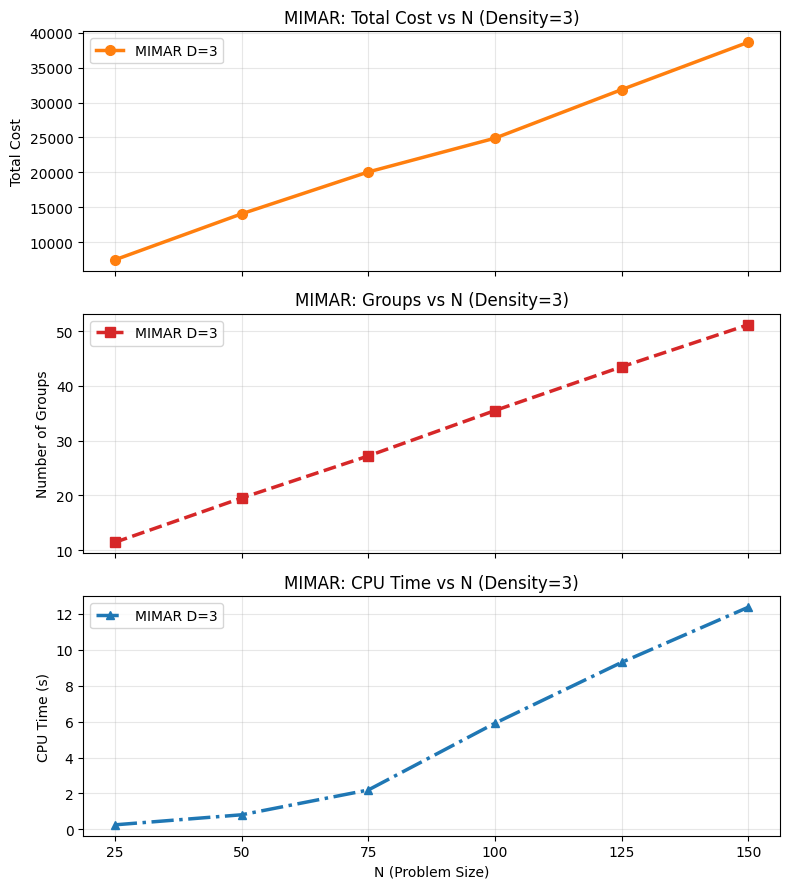

   ✅ MIMAR density 3 plot saved

📊 MIMAR density 10...


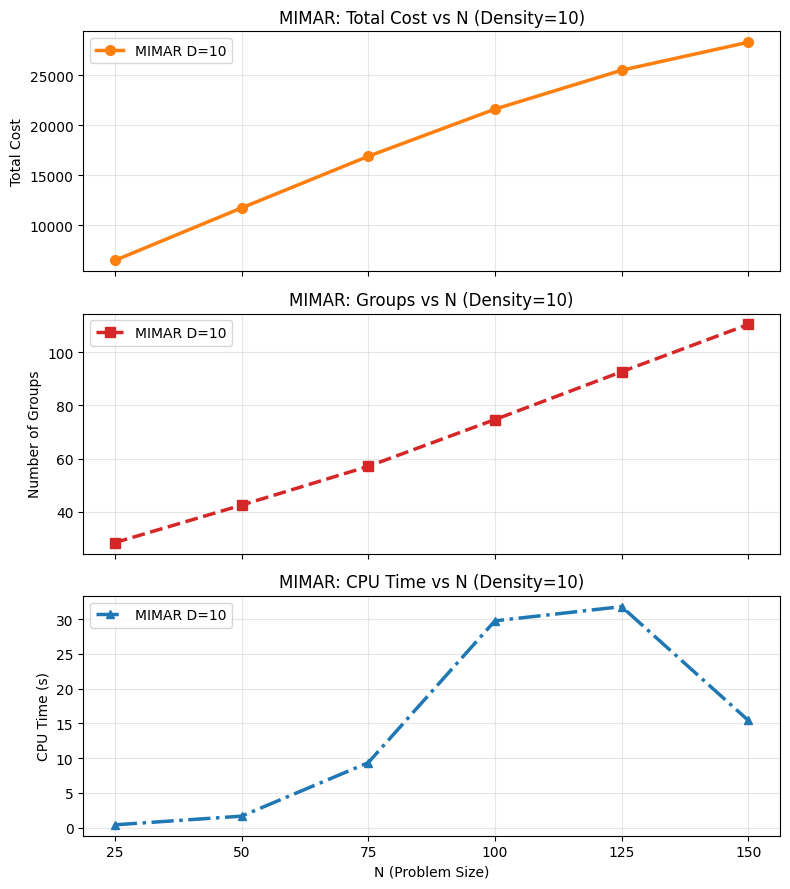

   ✅ MIMAR density 10 plot saved

📊 MIMAR density 20...


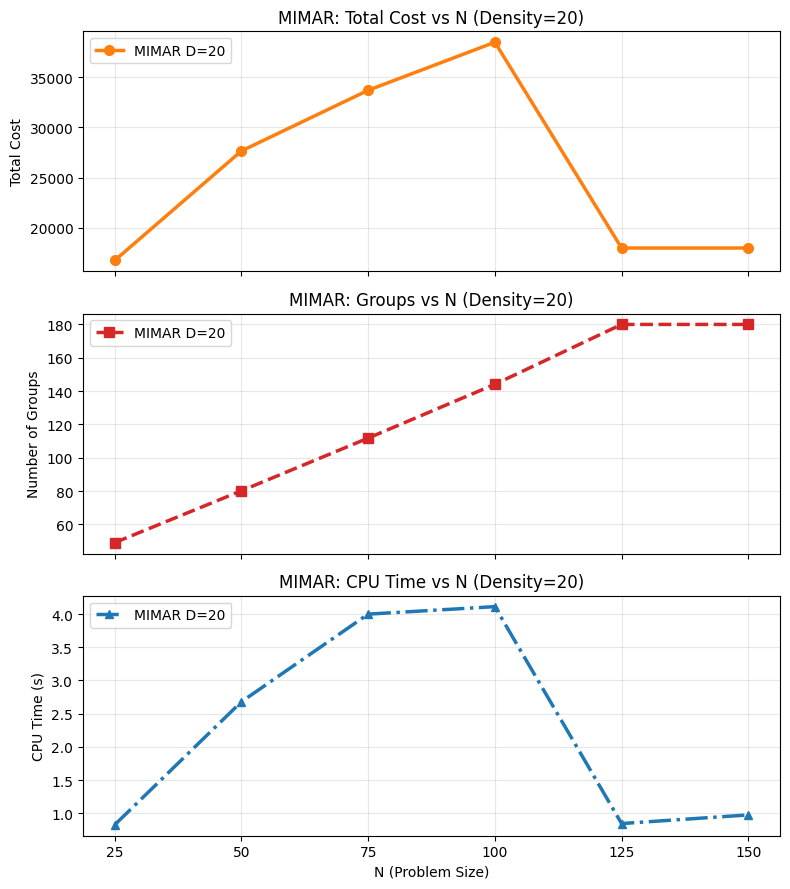

   ✅ MIMAR density 20 plot saved


In [5]:
# 🔥 MIMAR可视化（直接复制之前的修复版）
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import glob
import os

plt.rcParams["font.family"] = "DejaVu Sans"

def plot_N_sensitivity_per_density_MIMAR(results_dir='N_sensitivity_MIMAR_results_2026'):
    """MIMAR每个密度N敏感性分析图"""
    
    task_densities = [3, 10, 20]  # 🔥 你的密度
    
    summary_files = glob.glob(f"{results_dir}/SUMMARY_density_*_all_N.csv")
    if not summary_files:
        print(f"❌ No summary files in {results_dir}")
        return
    
    sample_df = pd.read_csv(summary_files[0])
    N_values = sorted(sample_df['N'].unique())
    print(f"🔍 MIMAR N values: {N_values}")
    
    for density in task_densities:
        print(f"\n📊 MIMAR density {density}...")
        
        summary_file = f"{results_dir}/SUMMARY_density_{density}_all_N.csv"
        if not os.path.exists(summary_file):
            print(f"⚠️  MIMAR file not found: {summary_file}")
            continue
            
        df = pd.read_csv(summary_file)
        agg_data = df.groupby('N').agg({
            'Total_cost': 'mean',
            'nb_groups': 'mean',
            'total_clustering_cpu_s': 'mean'
        }).round(3).reindex(N_values)
        
        N_plot = agg_data.index.dropna().tolist()
        
        fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)
        
        # Total Cost
        axes[0].plot(N_plot, agg_data.loc[N_plot, 'Total_cost'], "o-", color="#ff7f0e", linewidth=2.5, markersize=7, label=f"MIMAR D={density}")
        axes[0].set_ylabel("Total Cost")
        axes[0].set_title(f"MIMAR: Total Cost vs N (Density={density})")
        axes[0].legend(loc="upper left")
        axes[0].grid(True, alpha=0.3)
        
        # Groups
        axes[1].plot(N_plot, agg_data.loc[N_plot, 'nb_groups'], "s--", color="#d62728", linewidth=2.5, markersize=7, label=f"MIMAR D={density}")
        axes[1].set_ylabel("Number of Groups")
        axes[1].set_title(f"MIMAR: Groups vs N (Density={density})")
        axes[1].legend(loc="upper left")
        axes[1].grid(True, alpha=0.3)
        
        # CPU Time
        axes[2].plot(N_plot, agg_data.loc[N_plot, 'total_clustering_cpu_s'], "^-.", color="#1f77b4", linewidth=2.5, markersize=6, label=f"MIMAR D={density}")
        axes[2].set_xlabel("N (Problem Size)")
        axes[2].set_ylabel("CPU Time (s)")
        axes[2].set_title(f"MIMAR: CPU Time vs N (Density={density})")
        axes[2].legend(loc="upper left")
        axes[2].grid(True, alpha=0.3)
        axes[2].set_xticks(N_plot)
        
        plt.tight_layout()
        plt.savefig(f"{results_dir}/MIMAR_sensitivity_density_{density}_vs_N.png", dpi=300, bbox_inches='tight')
        plt.show()
        print(f"   ✅ MIMAR density {density} plot saved")

# 🔥 运行MIMAR可视化
if __name__ == "__main__":
    plot_N_sensitivity_per_density_MIMAR('N_sensitivity_MIMAR_results_2026')
